In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SelectKBest, mutual_info_classif

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../dataset/customer_churn_dataset-testing-master.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (64374, 12)


In [4]:

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (64374, 11)
Target shape: (64374,)


In [5]:
print("Feature names:")
print(X.columns.tolist())

print("\nData types:")
print(X.dtypes)

Feature names:
['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']

Data types:
CustomerID           int64
Age                  int64
Gender                 str
Tenure               int64
Usage Frequency      int64
Support Calls        int64
Payment Delay        int64
Subscription Type      str
Contract Length        str
Total Spend          int64
Last Interaction     int64
dtype: object


In [6]:
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Categorical features:")
print(categorical_features)

for column in categorical_features:
    print("\n" + "=" * 50)
    print("Feature:", column)
    print("Unique values:", X[column].unique())
    print("Number of unique values:", X[column].nunique())

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']

Feature: Gender
Unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Number of unique values: 2

Feature: Subscription Type
Unique values: <StringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str
Number of unique values: 3

Feature: Contract Length
Unique values: <StringArray>
['Monthly', 'Annual', 'Quarterly']
Length: 3, dtype: str
Number of unique values: 3


In [7]:
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Categorical features:")
print(categorical_features)

for column in categorical_features:
    print("\n" + "=" * 50)
    print("Feature:", column)
    print("Unique values:", X[column].unique())
    print("Number of unique values:", X[column].nunique())

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']

Feature: Gender
Unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Number of unique values: 2

Feature: Subscription Type
Unique values: <StringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str
Number of unique values: 3

Feature: Contract Length
Unique values: <StringArray>
['Monthly', 'Annual', 'Quarterly']
Length: 3, dtype: str
Number of unique values: 3


In [8]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))

print("\nDescriptive statistics:")
display(X[numerical_features].describe())

Numerical features:
['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

Number of numerical features: 8

Descriptive statistics:


,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000


In [9]:
# Remove CustomerID from the feature set
if "CustomerID" in X.columns:
    X = X.drop("CustomerID", axis=1)

print("CustomerID removed successfully.")
print("Number of remaining features:", X.shape[1])

print("\nRemaining features:")
print(X.columns.tolist())

CustomerID removed successfully.
Number of remaining features: 10

Remaining features:
['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']


In [10]:
# Encode the target variable
churn_encoded = y.map({"No": 0, "Yes": 1})

# Select numerical features
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

# Calculate correlation with Churn
correlation_with_churn = X[numerical_features].copy()
correlation_with_churn["Churn"] = churn_encoded

correlations = correlation_with_churn.corr()["Churn"].sort_values(
    ascending=False
)

print("Correlation of numerical features with Churn:")
display(correlations)

Correlation of numerical features with Churn:


Age                NaN
Tenure             NaN
Usage Frequency    NaN
Support Calls      NaN
Payment Delay      NaN
Total Spend        NaN
Last Interaction   NaN
Churn              NaN
Name: Churn, dtype: float64

In [11]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (51499, 10)
Testing features shape: (12875, 10)
Training target shape: (51499,)
Testing target shape: (12875,)


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same transformation to test data
X_test_processed = preprocessor.transform(X_test)

print("\nTraining data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Numerical features:
['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']

Training data after preprocessing: (51499, 15)
Testing data after preprocessing: (12875, 15)


In [13]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Select the top features
k = min(10, X_train_processed.shape[1])

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=k
)

# Fit feature selection only on training data
X_train_selected = selector.fit_transform(X_train_processed, y_train)

# Apply the same selection to test data
X_test_selected = selector.transform(X_test_processed)

# Get selected feature names
selected_features = feature_names[selector.get_support()]

print("Number of features before selection:", X_train_processed.shape[1])
print("Number of features selected:", X_train_selected.shape[1])

print("\nSelected features:")
for feature in selected_features:
    print(feature)

Number of features before selection: 15
Number of features selected: 10

Selected features:
num__Age
num__Tenure
num__Usage Frequency
num__Support Calls
num__Payment Delay
cat__Gender_Female
cat__Gender_Male
cat__Subscription Type_Premium
cat__Contract Length_Annual
cat__Contract Length_Quarterly


In [14]:
# Create a table of feature scores
feature_scores = pd.DataFrame({
    "Feature": feature_names,
    "Mutual Information Score": selector.scores_
})

# Sort features by score
feature_scores = feature_scores.sort_values(
    by="Mutual Information Score",
    ascending=False
)

print("Feature scores ranked by Mutual Information:")
display(feature_scores)

Feature scores ranked by Mutual Information:


,Feature,Mutual Information Score
4,num__Payment Delay,0.210780
3,num__Support Calls,0.063616
1,num__Tenure,0.029569
8,cat__Gender_Male,0.019961
2,num__Usage Frequency,0.016463
7,cat__Gender_Female,0.015799
14,cat__Contract Length_Quarterly,0.005977
0,num__Age,0.004027
10,cat__Subscription Type_Premium,0.003889
12,cat__Contract Length_Annual,0.003263


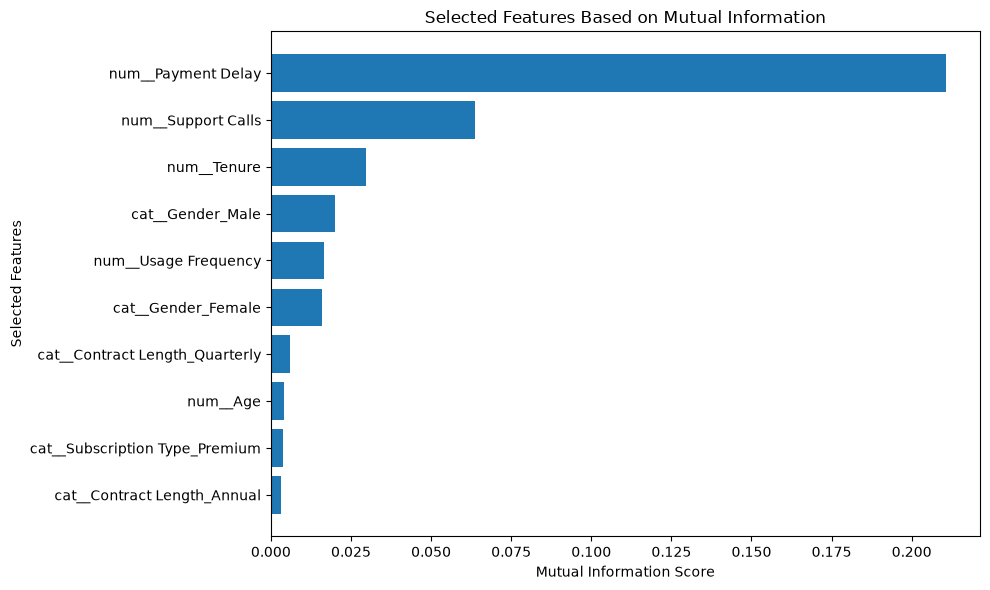

In [15]:
# Get scores of selected features
selected_feature_scores = feature_scores[
    feature_scores["Feature"].isin(selected_features)
].sort_values(
    by="Mutual Information Score",
    ascending=True
)

# Plot selected feature scores
plt.figure(figsize=(10, 6))

plt.barh(
    selected_feature_scores["Feature"],
    selected_feature_scores["Mutual Information Score"]
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Selected Features")
plt.title("Selected Features Based on Mutual Information")

plt.tight_layout()
plt.show()

In [16]:
print("FEATURE ENGINEERING AND SELECTION SUMMARY")
print("=" * 50)

print("Features before selection:", X_train_processed.shape[1])
print("Features after selection:", X_train_selected.shape[1])

print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

print("\nFeature engineering and selection completed successfully!")

FEATURE ENGINEERING AND SELECTION SUMMARY
Features before selection: 15
Features after selection: 10

Selected features:
- num__Age
- num__Tenure
- num__Usage Frequency
- num__Support Calls
- num__Payment Delay
- cat__Gender_Female
- cat__Gender_Male
- cat__Subscription Type_Premium
- cat__Contract Length_Annual
- cat__Contract Length_Quarterly

Feature engineering and selection completed successfully!
